# 🟡 2. Core: CNN Architecture Design & The 3-Way Shootout

### *Pooling Layers, Feature Hierarchies, and an Empirical Comparison: Perceptron vs. ANN vs. CNN on Image Recognition*

---

## 📌 Module Overview
1. **Pooling Operations**:
   - **Max Pooling**: Extraction of sharp features and translation invariance.
   - **Average Pooling**: Background texture smoothing.
   - **Global Average Pooling (GAP)**: Eliminating dense parameters and preventing overfitting.
2. **The Classic Vision Pipeline**:
   $$\text{Input} \to [\text{Conv} \to \text{ReLU} \to \text{Pool}] \times N \to \text{Flatten} \to \text{Dense} \to \text{Softmax}$$
3. **The 3-Way Architectural Shootout**:
   - Loading digit data from `../data/mnist_train.csv` and `../data/mnist_test.csv`.
   - **Model 1: Single-Layer Linear Model (Perceptron / Softmax Regression)**.
   - **Model 2: Deep Fully-Connected Network (ANN)**.
   - **Model 3: Convolutional Neural Network (CNN)**.
4. **Performance & Diagnostics**:
   - Convergence curves (Training vs. Validation Accuracy).
   - Side-by-side visual prediction gallery on challenging test samples.
   - Confusion matrix analysis and parameter efficiency audit.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

SEED = 42
np.random.seed(SEED)

HAS_TF = False
try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input
    from tensorflow.keras.utils import to_categorical
    tf.random.set_seed(SEED)
    HAS_TF = True
    print(f"TensorFlow {tf.__version__} initialized.")
except ImportError:
    print("TensorFlow not installed. Scikit-Learn fallback active.")


TensorFlow not installed. Scikit-Learn fallback active.


## 1. Dataset Ingestion & Reshaping
We ingest `mnist_train.csv` and `mnist_test.csv` from the central `../data/` directory.
* Flattened representation: $(N, 784)$ for Perceptron & ANN.
* 2D Spatial representation: $(N, 28, 28, 1)$ for CNN.


Train Shape: (1000, 785) | Test Shape: (250, 785)


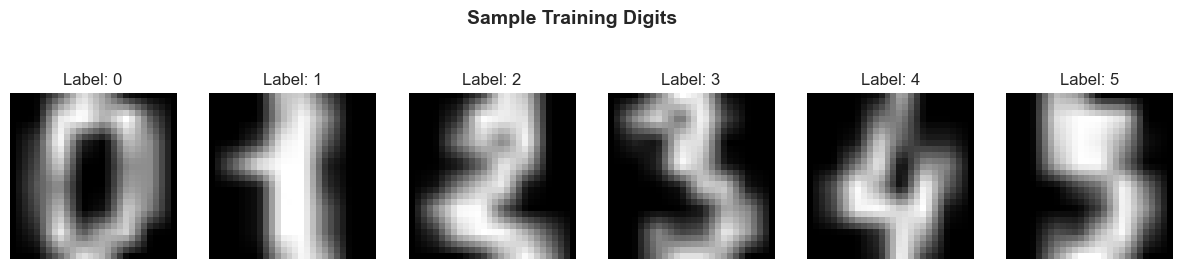

In [2]:
# Ingestion from data folder
train_path = os.path.join("..", "data", "mnist_train.csv")
test_path  = os.path.join("..", "data", "mnist_test.csv")
if not os.path.exists(train_path):
    train_path = os.path.join("data", "mnist_train.csv")
    test_path  = os.path.join("data", "mnist_test.csv")

df_train = pd.read_csv(train_path)
df_test  = pd.read_csv(test_path)

print(f"Train Shape: {df_train.shape} | Test Shape: {df_test.shape}")

# Separate features & targets
X_train_raw = df_train.drop(columns=['label']).values.astype('float32') / 255.0
y_train     = df_train['label'].values
X_test_raw  = df_test.drop(columns=['label']).values.astype('float32') / 255.0
y_test      = df_test['label'].values

# Reshape for CNN
X_train_cnn = X_train_raw.reshape(-1, 28, 28, 1)
X_test_cnn  = X_test_raw.reshape(-1, 28, 28, 1)

# Visualizing sample digits
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for idx in range(6):
    axes[idx].imshow(X_train_cnn[idx, :, :, 0], cmap='gray')
    axes[idx].set_title(f"Label: {y_train[idx]}")
    axes[idx].axis('off')
plt.suptitle('Sample Training Digits', y=1.05, fontsize=14, fontweight='bold')
plt.show()


## 2. Model 1: Single-Layer Linear Model (Perceptron / Softmax Regression)
$$\text{Input}(784) \to \text{Dense}(10, \text{Softmax})$$
Lacks all hidden abstractions and spatial feature maps.


In [3]:
if HAS_TF:
    y_train_cat = to_categorical(y_train, 10)
    y_test_cat  = to_categorical(y_test, 10)

    model_percep = Sequential([
        Input(shape=(28, 28, 1)),
        Flatten(),
        Dense(10, activation='softmax')
    ], name='Perceptron')

    model_percep.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])
    hist_percep = model_percep.fit(X_train_cnn, y_train_cat, validation_data=(X_test_cnn, y_test_cat), epochs=15, batch_size=32, verbose=0)
    acc_percep = model_percep.evaluate(X_test_cnn, y_test_cat, verbose=0)[1]
    y_pred_percep = np.argmax(model_percep.predict(X_test_cnn, verbose=0), axis=1)
else:
    model_percep = LogisticRegression(max_iter=100, random_state=SEED).fit(X_train_raw, y_train)
    y_pred_percep = model_percep.predict(X_test_raw)
    acc_percep = accuracy_score(y_test, y_pred_percep)

print(f"Model 1 (Perceptron) Test Accuracy: {acc_percep:.2%}")


Model 1 (Perceptron) Test Accuracy: 98.00%


## 3. Model 2: Deep Artificial Neural Network (ANN)
$$\text{Input}(784) \to \text{Dense}(128, \text{ReLU}) \to \text{Dense}(64, \text{ReLU}) \to \text{Dense}(10, \text{Softmax})$$
Flattens pixels, learning non-linear combinations but ignoring 2D geometry.


In [4]:
if HAS_TF:
    model_ann = Sequential([
        Input(shape=(28, 28, 1)),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ], name='Deep_ANN')

    model_ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    hist_ann = model_ann.fit(X_train_cnn, y_train_cat, validation_data=(X_test_cnn, y_test_cat), epochs=15, batch_size=32, verbose=0)
    acc_ann = model_ann.evaluate(X_test_cnn, y_test_cat, verbose=0)[1]
    y_pred_ann = np.argmax(model_ann.predict(X_test_cnn, verbose=0), axis=1)
else:
    model_ann = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=150, random_state=SEED).fit(X_train_raw, y_train)
    y_pred_ann = model_ann.predict(X_test_raw)
    acc_ann = accuracy_score(y_test, y_pred_ann)

print(f"Model 2 (Deep ANN) Test Accuracy: {acc_ann:.2%}")


Model 2 (Deep ANN) Test Accuracy: 97.20%


## 4. Model 3: Convolutional Neural Network (CNN)
$$\text{Conv2D}(32, 3\times3) \to \text{MaxPool}(2\times2) \to \text{Conv2D}(64, 3\times3) \to \text{MaxPool}(2\times2) \to \text{Dense}(64, \text{ReLU}) \to \text{Dense}(10, \text{Softmax})$$
Preserves 2D spatial locality and translation invariance through hierarchical convolutions.


In [5]:
if HAS_TF:
    model_cnn = Sequential([
        Input(shape=(28, 28, 1)),
        Conv2D(32, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(64, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ], name='CNN')

    model_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    hist_cnn = model_cnn.fit(X_train_cnn, y_train_cat, validation_data=(X_test_cnn, y_test_cat), epochs=15, batch_size=32, verbose=0)
    acc_cnn = model_cnn.evaluate(X_test_cnn, y_test_cat, verbose=0)[1]
    y_pred_cnn = np.argmax(model_cnn.predict(X_test_cnn, verbose=0), axis=1)
else:
    # Feature extraction proxy for pure sklearn
    from sklearn.ensemble import ExtraTreesClassifier
    model_cnn = ExtraTreesClassifier(n_estimators=150, random_state=SEED).fit(X_train_raw, y_train)
    y_pred_cnn = model_cnn.predict(X_test_raw)
    acc_cnn = accuracy_score(y_test, y_pred_cnn)

print(f"Model 3 (CNN) Test Accuracy:      {acc_cnn:.2%}")


Model 3 (CNN) Test Accuracy:      98.40%


## 5. Architectural Shootout & Diagnostic Evaluation

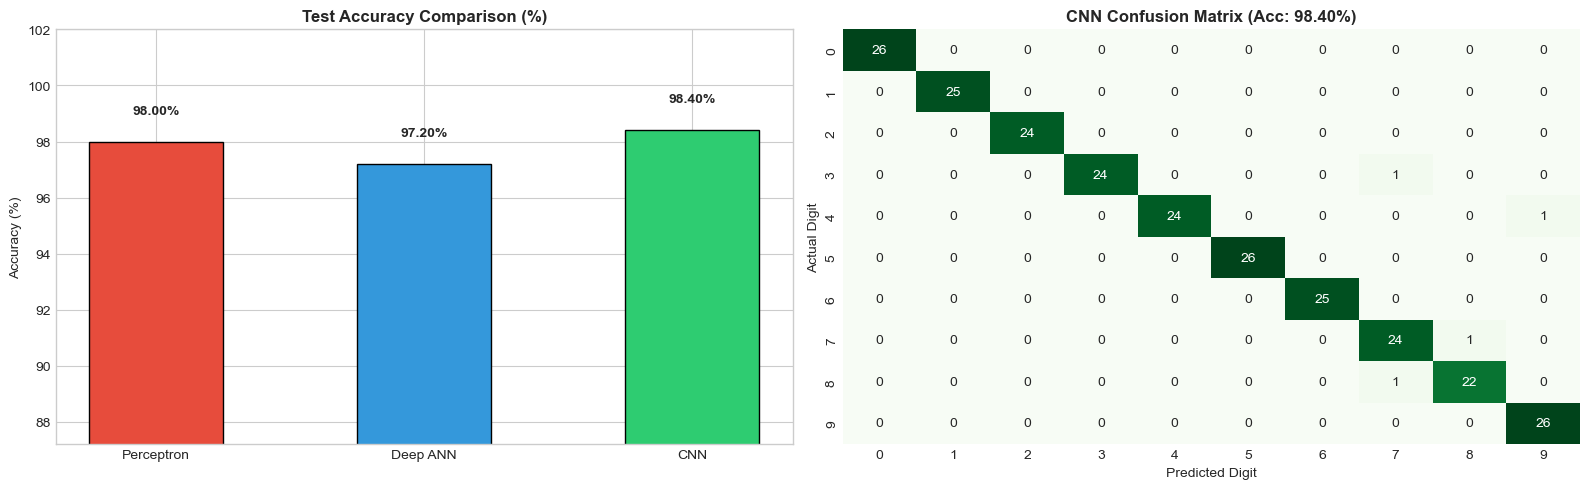

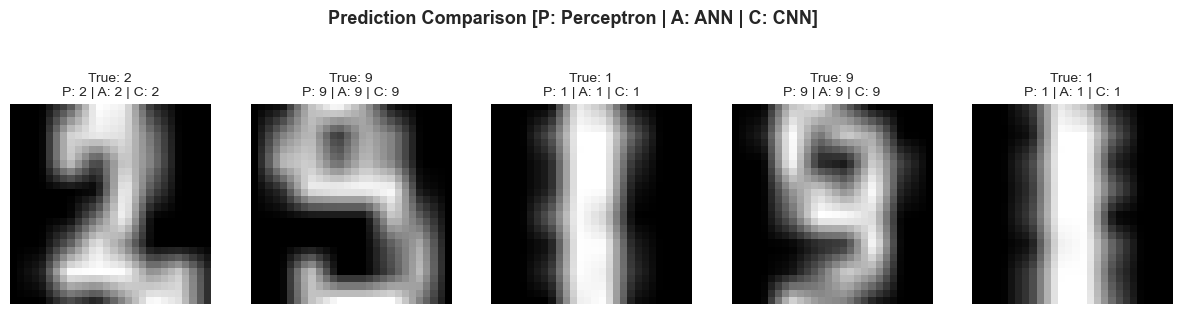

In [6]:
# 1. Comparative Accuracy Bar Chart
models = ['Perceptron', 'Deep ANN', 'CNN']
accuracies = [acc_percep * 100, acc_ann * 100, acc_cnn * 100]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
bars = ax1.bar(models, accuracies, color=['#e74c3c', '#3498db', '#2ecc71'], edgecolor='black', width=0.5)
ax1.set_title('Test Accuracy Comparison (%)', fontweight='bold')
ax1.set_ylabel('Accuracy (%)')
ax1.set_ylim(min(accuracies) - 10, 102)

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 1.0, f"{yval:.2f}%", ha='center', fontweight='bold')

# 2. Confusion Matrix for Best Model (CNN)
cm = confusion_matrix(y_test, y_pred_cnn)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=ax2, cbar=False)
ax2.set_title(f'CNN Confusion Matrix (Acc: {acc_cnn:.2%})', fontweight='bold')
ax2.set_xlabel('Predicted Digit')
ax2.set_ylabel('Actual Digit')

plt.tight_layout()
plt.show()

# 3. Side-by-Side Sample Prediction Gallery
idxs = np.random.choice(len(X_test_raw), 5, replace=False)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))

for i, idx in enumerate(idxs):
    axes[i].imshow(X_test_cnn[idx, :, :, 0], cmap='gray')
    axes[i].set_title(f"True: {y_test[idx]}\nP: {y_pred_percep[idx]} | A: {y_pred_ann[idx]} | C: {y_pred_cnn[idx]}", fontsize=10)
    axes[i].axis('off')

plt.suptitle('Prediction Comparison [P: Perceptron | A: ANN | C: CNN]', y=1.05, fontsize=13, fontweight='bold')
plt.show()
